# Manufacturing Analytics: BOM Costing & Production Planning

**Context.** In my role at a furniture manufacturer (melamine and sheet-metal furniture, ~30 employees) I built the company's first costing model and a production planning system based on bills of materials (BOM). The real data is confidential, so this project **reproduces the same approach with a fictional dataset** of 10 products.

**Business questions**
1. What does each product really cost (materials + labor + overhead)?
2. Which products are underpriced, and what price would reach the target margin?
3. Based on recent sales, what do we need to produce and which materials do we need to buy?

**Tools:** Python (pandas, Matplotlib), Excel export (openpyxl).

**Data** (`data/`, generated with `generate_data.py`):

| File | Content |
|---|---|
| `materials.csv` | 13 raw materials: unit cost, stock, minimum stock, lead time |
| `subassemblies.csv` | 4 parts made in-house (metal frames, drawer box) and their labor time |
| `products.csv` | 10 finished products: list price and assembly labor time |
| `bom.csv` | Multi-level bill of materials (product → subassembly → material) |
| `sales.csv` | Monthly units sold, Jan–Oct 2025 |
| `finished_goods_stock.csv` | Finished products in stock |
| `overhead.csv` | Monthly fixed costs (rent, energy, supervision, …) |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

materials = pd.read_csv("data/materials.csv")
subassemblies = pd.read_csv("data/subassemblies.csv")
products = pd.read_csv("data/products.csv")
bom = pd.read_csv("data/bom.csv")
sales = pd.read_csv("data/sales.csv")
fg_stock = pd.read_csv("data/finished_goods_stock.csv")
overhead = pd.read_csv("data/overhead.csv")

# Business assumptions
LABOR_COST_PER_HOUR = 6.0   # USD, fully loaded
CHANNEL_FEE = 0.15          # marketplace / e-commerce commission on the list price
TARGET_MARGIN = 0.30        # target net margin

bom.head(8)

,parent_id,component_id,qty
0,S01,M05,7.50
1,S01,M07,0.35
2,S01,M13,4.00
3,S02,M05,4.00
4,S02,M07,0.20
5,S02,M13,4.00
6,S03,M01,0.35
7,S03,M03,0.18


## 1. Exploding the multi-level BOM

Some products use subassemblies made in-house (e.g. the industrial desk uses a metal frame, which is made of steel tube, paint and leveling feet). To get the real cost, the BOM has to be **exploded recursively** down to raw materials, multiplying quantities at each level.

In [2]:
sub_labor = subassemblies.set_index("item_id")["labor_minutes"]

def explode(item_id, qty=1.0):
    """Returns the raw materials (and labor minutes of subassemblies) needed for `qty` units of an item."""
    rows, labor = [], 0.0
    for _, r in bom[bom["parent_id"] == item_id].iterrows():
        q = qty * r["qty"]
        if r["component_id"].startswith("S"):            # subassembly -> go one level down
            sub_rows, sub_labor_min = explode(r["component_id"], q)
            rows += sub_rows
            labor += sub_labor_min + q * sub_labor[r["component_id"]]
        else:                                            # raw material
            rows.append((r["component_id"], q))
    return rows, labor

# Example: industrial desk (P02)
rows, sub_minutes = explode("P02")
example = (pd.DataFrame(rows, columns=["material_id", "qty"])
             .groupby("material_id", as_index=False)["qty"].sum()
             .merge(materials[["material_id", "material", "unit", "unit_cost"]], on="material_id"))
example["cost"] = example["qty"] * example["unit_cost"]
print(f"Labor in subassemblies: {sub_minutes:.0f} min")
example

Labor in subassemblies: 25 min


,material_id,qty,material,unit,unit_cost,cost
0,M02,1.20,Melamine board 18mm (oak),m2,11.20,13.44
1,M04,5.00,PVC edge banding,m,0.35,1.75
2,M05,7.50,Steel square tube 20x20,m,2.40,18.00
3,M07,0.35,Epoxy powder paint (black),kg,8.90,3.11
4,M11,1.00,Screws and fittings kit,kit,1.90,1.90
5,M12,1.00,Packaging (cardboard box),unit,4.20,4.20
6,M13,4.00,Adjustable leveling foot,unit,0.55,2.20


## 2. Full unit cost per product

In [3]:
unit_cost = materials.set_index("material_id")["unit_cost"]

records = []
for p in products.itertuples():
    rows, sub_minutes = explode(p.product_id)
    mat_cost = sum(q * unit_cost[m] for m, q in rows)
    records.append((p.product_id, mat_cost, p.labor_minutes + sub_minutes))

cost = products.merge(pd.DataFrame(records, columns=["product_id", "material_cost", "total_labor_min"]),
                      on="product_id")

# Overhead is allocated by labor minutes, using average monthly volume
avg_units = sales.groupby("product_id")["units_sold"].mean().rename("avg_monthly_units")
cost = cost.merge(avg_units, on="product_id")
monthly_minutes = (cost["total_labor_min"] * cost["avg_monthly_units"]).sum()
overhead_per_minute = overhead["usd_per_month"].sum() / monthly_minutes

cost["labor_cost"] = cost["total_labor_min"] / 60 * LABOR_COST_PER_HOUR
cost["overhead_cost"] = cost["total_labor_min"] * overhead_per_minute
cost["full_cost"] = cost[["material_cost", "labor_cost", "overhead_cost"]].sum(axis=1)

print(f"Monthly overhead: USD {overhead['usd_per_month'].sum():,.0f}  |  "
      f"allocated at USD {overhead_per_minute:.2f} per labor minute")
cost[["product", "material_cost", "labor_cost", "overhead_cost", "full_cost"]]

Monthly overhead: USD 7,250  |  allocated at USD 0.46 per labor minute


,product,material_cost,labor_cost,overhead_cost,full_cost
0,Office desk 120cm,36.21,5.70,26.24,68.16
1,Industrial desk 140cm,44.61,8.00,36.83,89.44
2,Bookshelf 5 levels,46.75,4.00,18.42,69.17
3,Industrial metal shelf,71.78,6.50,29.93,108.20
4,Bedside table 1 drawer,28.74,4.20,19.34,52.27
5,Chest of drawers 4,81.12,11.30,52.02,144.45
6,Wardrobe 2 doors,101.89,8.00,36.83,146.72
7,TV stand 160cm,45.24,4.50,20.72,70.46
8,Industrial side table,24.08,3.50,16.11,43.70
9,Shoe cabinet 3 doors,45.86,4.00,18.42,68.28


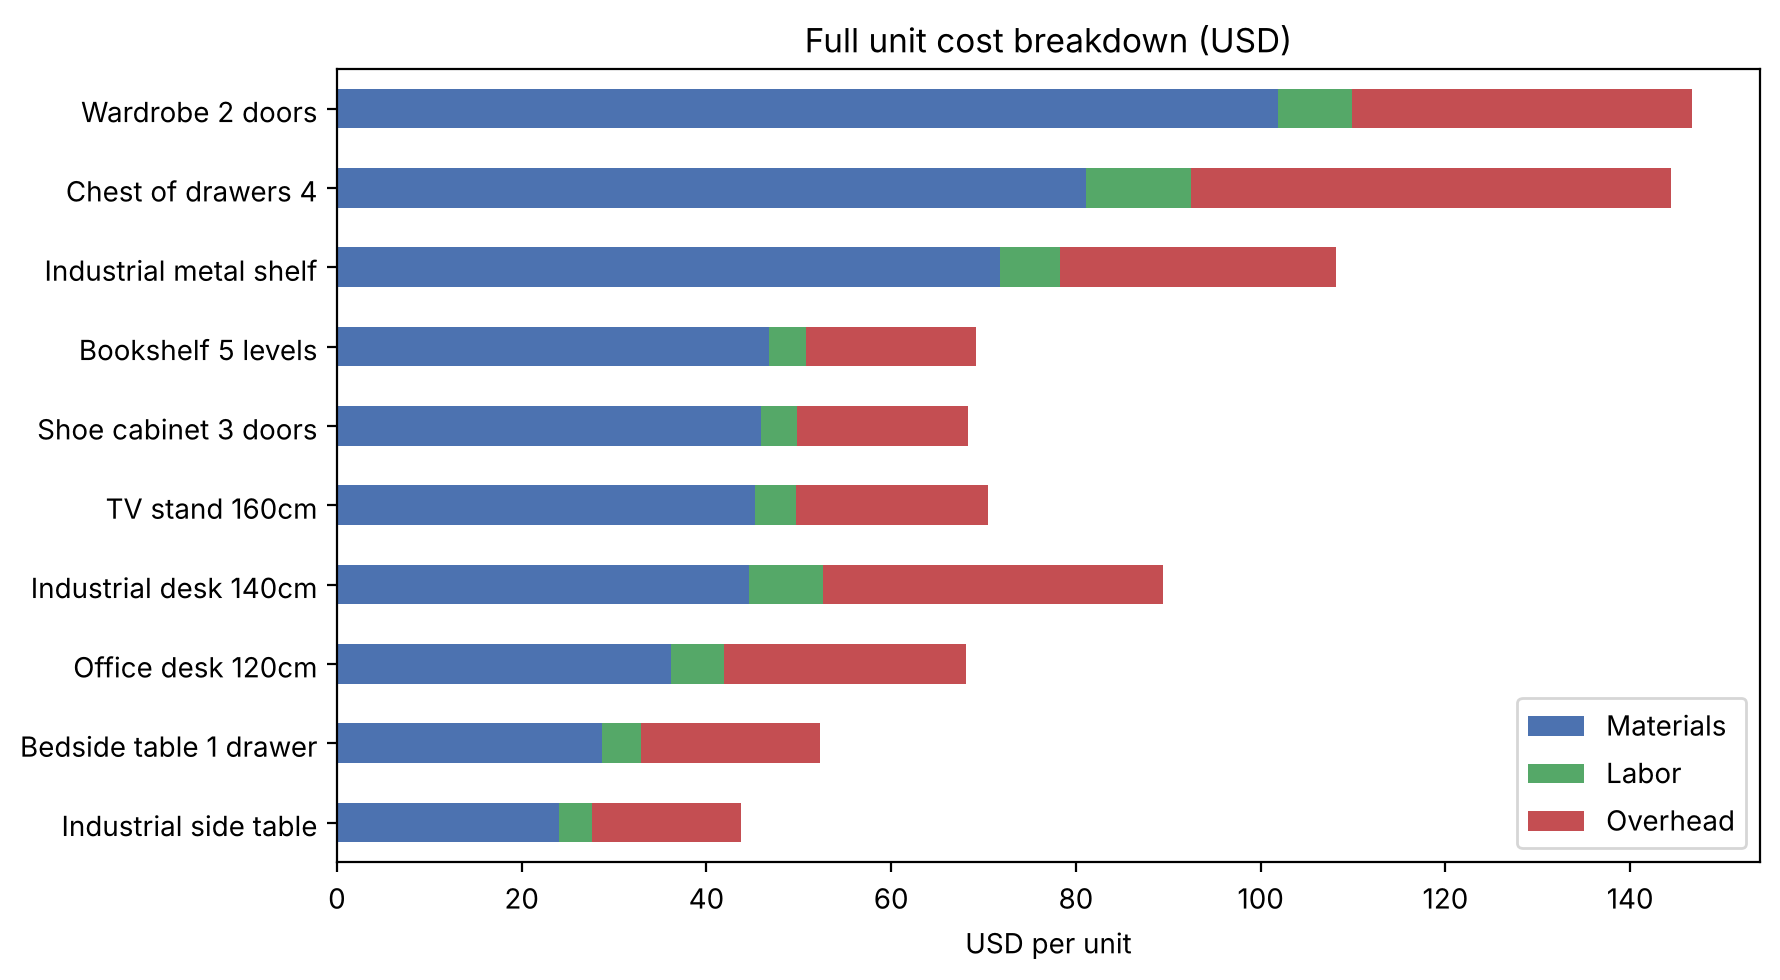

In [4]:
ax = (cost.set_index("product")[["material_cost", "labor_cost", "overhead_cost"]]
          .sort_values("material_cost")
          .plot(kind="barh", stacked=True, figsize=(9, 5),
                color=["#4C72B0", "#55A868", "#C44E52"]))
ax.set_title("Full unit cost breakdown (USD)")
ax.set_xlabel("USD per unit")
ax.set_ylabel("")
ax.legend(["Materials", "Labor", "Overhead"])
plt.tight_layout()
plt.show()

## 3. Margin analysis

The list price is not what the company receives: e-commerce and marketplace channels charge a commission (15% here). The margin is calculated on the **net price**.

In [5]:
cost["net_price"] = cost["list_price"] * (1 - CHANNEL_FEE)
cost["unit_profit"] = cost["net_price"] - cost["full_cost"]
cost["margin"] = cost["unit_profit"] / cost["net_price"]
cost["monthly_profit"] = cost["unit_profit"] * cost["avg_monthly_units"]

# Price needed to reach the target margin (only for products below target)
cost["below_target"] = cost["margin"] < TARGET_MARGIN
price_for_target = cost["full_cost"] / (1 - TARGET_MARGIN) / (1 - CHANNEL_FEE)
cost["suggested_list_price"] = price_for_target.where(cost["below_target"], cost["list_price"])

margins = cost.sort_values("margin")[["product", "list_price", "full_cost", "net_price",
                                      "margin", "suggested_list_price", "monthly_profit"]]
margins.style.format({"list_price": "{:,.0f}", "full_cost": "{:,.2f}", "net_price": "{:,.2f}",
                      "margin": "{:.0%}", "suggested_list_price": "{:,.0f}",
                      "monthly_profit": "{:,.0f}"})

,product,list_price,full_cost,net_price,margin,suggested_list_price,monthly_profit
5,Chest of drawers 4,179,144.45,152.15,5%,243,153
4,Bedside table 1 drawer,69,52.27,58.65,11%,88,395
3,Industrial metal shelf,159,108.20,135.15,20%,182,490
9,Shoe cabinet 3 doors,119,68.28,101.15,33%,119,727
6,Wardrobe 2 doors,259,146.72,220.15,33%,259,866
8,Industrial side table,79,43.70,67.15,35%,79,600
2,Bookshelf 5 levels,139,69.17,118.15,41%,139,"2,219"
7,TV stand 160cm,149,70.46,126.65,44%,149,"1,641"
0,Office desk 120cm,149,68.16,126.65,46%,149,"2,123"
1,Industrial desk 140cm,199,89.44,169.15,47%,199,"1,802"


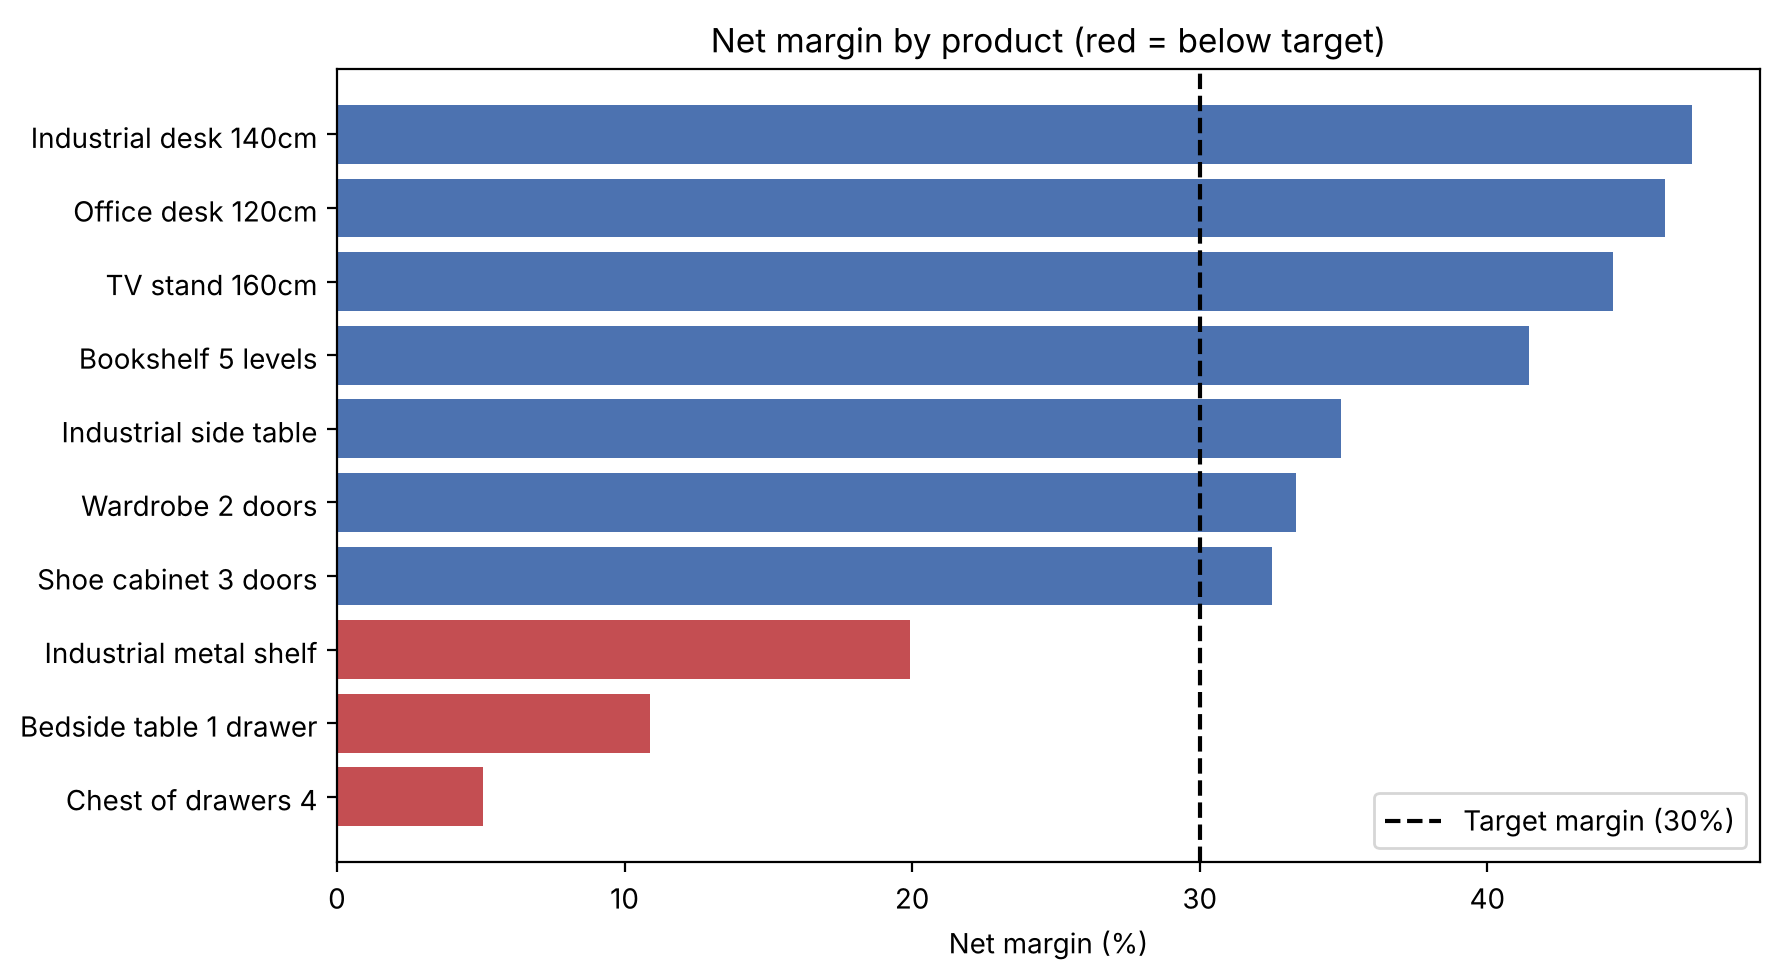

In [6]:
plot_df = cost.sort_values("margin")
colors = ["#C44E52" if m < TARGET_MARGIN else "#4C72B0" for m in plot_df["margin"]]

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df["product"], plot_df["margin"] * 100, color=colors)
ax.axvline(TARGET_MARGIN * 100, color="black", linestyle="--", label=f"Target margin ({TARGET_MARGIN:.0%})")
ax.set_xlabel("Net margin (%)")
ax.set_title("Net margin by product (red = below target)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Why are some products less profitable?

Two of the three products below target use the **drawer box** (subassembly S03), which includes drawer slides, board and fittings plus 12 minutes of labor. How much of their cost does it represent?

In [7]:
rows = []
for p in products.itertuples():
    uses_drawers = int(bom[(bom["parent_id"] == p.product_id) & (bom["component_id"] == "S03")]["qty"].sum())
    rows.append((p.product_id, uses_drawers))
drawers = pd.DataFrame(rows, columns=["product_id", "drawer_boxes"])

drawer_cost = sum(q * unit_cost[m] for m, q in explode("S03")[0]) \
              + sub_labor["S03"] / 60 * LABOR_COST_PER_HOUR + sub_labor["S03"] * overhead_per_minute
print(f"Full cost of one drawer box: USD {drawer_cost:.2f}")

(cost.merge(drawers, on="product_id")
     .assign(drawer_share_of_cost=lambda d: d["drawer_boxes"] * drawer_cost / d["full_cost"])
     .query("drawer_boxes > 0")
     [["product", "drawer_boxes", "full_cost", "drawer_share_of_cost", "margin"]]
     .style.format({"full_cost": "{:,.2f}", "drawer_share_of_cost": "{:.0%}", "margin": "{:.0%}"}))

Full cost of one drawer box: USD 15.59


,product,drawer_boxes,full_cost,drawer_share_of_cost,margin
0,Office desk 120cm,1,68.16,23%,46%
4,Bedside table 1 drawer,1,52.27,30%,11%
5,Chest of drawers 4,4,144.45,43%,5%


## 5. Production and purchase planning for next month

1. **Demand forecast:** average of the last 3 months of sales.
2. **Production plan:** forecast minus finished goods in stock.
3. **Material requirements (MRP):** explode the production plan through the BOM.
4. **Purchases:** buy what is needed to cover production and keep each material at its minimum stock.

In [8]:
last_3 = sorted(sales["month"].unique())[-3:]
forecast = (sales[sales["month"].isin(last_3)]
            .groupby("product_id")["units_sold"].mean().round().astype(int)
            .rename("forecast_units"))

plan = (products[["product_id", "product"]]
        .merge(forecast, on="product_id")
        .merge(fg_stock, on="product_id"))
plan["to_produce"] = (plan["forecast_units"] - plan["units_in_stock"]).clip(lower=0)
print(f"Forecast based on: {', '.join(last_3)}")
plan

Forecast based on: 2025-08, 2025-09, 2025-10


,product_id,product,forecast_units,units_in_stock,to_produce
0,P01,Office desk 120cm,40,12,28
1,P02,Industrial desk 140cm,24,4,20
2,P03,Bookshelf 5 levels,52,20,32
3,P04,Industrial metal shelf,19,2,17
4,P05,Bedside table 1 drawer,68,25,43
5,P06,Chest of drawers 4,23,3,20
6,P07,Wardrobe 2 doors,13,1,12
7,P08,TV stand 160cm,34,10,24
8,P09,Industrial side table,30,8,22
9,P10,Shoe cabinet 3 doors,25,6,19


In [9]:
req_rows = []
for p in plan.itertuples():
    if p.to_produce > 0:
        req_rows += explode(p.product_id, p.to_produce)[0]

requirements = (pd.DataFrame(req_rows, columns=["material_id", "required"])
                  .groupby("material_id", as_index=False)["required"].sum())

mrp = materials.merge(requirements, on="material_id", how="left").fillna({"required": 0})
mrp["stock_after_production"] = mrp["stock"] - mrp["required"]
mrp["to_buy"] = (mrp["min_stock"] - mrp["stock_after_production"]).clip(lower=0).round(1)
mrp["purchase_cost"] = mrp["to_buy"] * mrp["unit_cost"]

purchases = (mrp[mrp["to_buy"] > 0]
             .sort_values("lead_time_days", ascending=False)
             [["material", "unit", "stock", "required", "min_stock", "to_buy", "lead_time_days", "purchase_cost"]])
print(f"Total purchase order: USD {purchases['purchase_cost'].sum():,.0f}")
purchases

Total purchase order: USD 9,254


,material,unit,stock,required,min_stock,to_buy,lead_time_days,purchase_cost
8,Hinge 35mm,unit,420,282.00,300,162.00,15,137.70
9,Handle 128mm,unit,230,280.00,150,200.00,15,280.00
12,Adjustable leveling foot,unit,400,552.00,300,452.00,15,248.60
7,Drawer slide (pair),unit,90,151.00,80,141.00,15,648.60
4,Steel square tube 20x20,m,260,391.00,200,331.00,10,794.40
5,Steel sheet 0.9mm,m2,25,27.20,30,32.20,10,476.56
6,Epoxy powder paint (black),kg,18,20.75,15,17.80,10,158.42
1,Melamine board 18mm (oak),m2,140,107.40,120,87.40,7,978.88
0,Melamine board 18mm (white),m2,220,420.35,150,350.30,7,"3,327.85"
2,Fiberboard back panel 3mm,m2,160,148.53,80,68.50,7,212.35


## 6. Export results to Excel
The output is a workbook the purchasing and management teams can use directly.

In [10]:
with pd.ExcelWriter("output/costing_and_planning.xlsx") as writer:
    cost.round(2).to_excel(writer, sheet_name="Costs & margins", index=False)
    plan.to_excel(writer, sheet_name="Production plan", index=False)
    mrp.round(2).to_excel(writer, sheet_name="Material requirements", index=False)
    purchases.round(2).to_excel(writer, sheet_name="Purchase order", index=False)
print("Saved output/costing_and_planning.xlsx")

Saved output/costing_and_planning.xlsx


## Conclusions

**Costing and pricing**
- **3 of the 10 products are below the 30% target margin:** Chest of drawers (5%), Bedside table (11%) and Industrial metal shelf (20%). The chest of drawers earns less than USD 8 per unit after the channel fee.
- **Drawers are the main cost driver** in the two worst products: one drawer box costs USD 15.59, which is 43% of the chest of drawers' cost and 30% of the bedside table's.
- The **metal shelf** has a different problem: materials (mostly steel tube and sheet) are 66% of its cost.
- **Price to reach the target:** Chest of drawers USD 243 (now 179), Bedside table USD 88 (now 69), Metal shelf USD 182 (now 159). If the market does not accept those prices, the alternative is reducing cost: cheaper drawer slides, fewer drawers, or less steel in the shelf design.
- The **Bookshelf and the Office desk generate ~40% of the monthly profit**, so they should never run out of stock.

**Production and purchasing (next month)**
- Forecast demand requires producing **237 units** after using finished goods in stock.
- The purchase order to cover production and keep minimum stock is **USD 9,254**. White melamine board alone is 36% of it.
- Items with the longest lead time (15 days: drawer slides, hinges, handles, leveling feet) should be ordered first to avoid stopping production.

**Next steps:** replace the 3-month average with a seasonal forecast, and track actual vs standard cost every month to detect deviations early.